In [1]:
!apt-get -qq install -y zstd > /dev/null
!curl -fsSL https://ollama.com/install.sh | sh
!pip -q install ollama pymupdf openai

>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%                                                               7.4%#############################                                         46.8%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [2]:
import subprocess, time, glob, json, re, hashlib, base64, datetime
from pathlib import Path

subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(5)

PDFS = {re.search(r"bilan_group_(\d+)", p).group(1): p for p in glob.glob("/kaggle/input/**/bilan_group_*.pdf", recursive=True)}
RESULTS = Path("/kaggle/working/results")
RESULTS.mkdir(exist_ok=True)
print("bilans found:", sorted(PDFS, key=int))

bilans found: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']


In [3]:
from kaggle_secrets import UserSecretsClient
from openai import OpenAI

api = OpenAI(base_url="https://openrouter.ai/api/v1", api_key=UserSecretsClient().get_secret("OPENROUTER_API_KEY"))

In [4]:
QWEN25 = "qwen2.5vl:7b"
NEMOTRON = "nvidia/nemotron-3.5-super-vl:free"
JSON_SCHEMA_OK = {NEMOTRON}

!ollama pull {QWEN25}

]11;?\pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest 
pulling a99b7f834d75:   0% ▕                  ▏ 259 KB/6.0 GB                  pulling manifest 
pulling a99b7f834d75:   1% ▕                  ▏  68 MB/6.0 GB                  pulling manifest 
pulling a99b7f834d75:   3% ▕                  ▏ 151 MB/6.0 GB                  pulling manifest 
pulling a99b7f834d75:   3% ▕                  ▏ 201 MB/6.0 GB                  pulling manifest 
pulling a99b7f834d75:   5% ▕                  ▏ 292 MB/6.0 GB                  pulling manifest 
pulling a99b7f834d75:   6% ▕█                 ▏ 378 MB/6.0 GB                  pulling manifest 
pulling a99b7f834d75:   7% ▕█                 ▏ 436 MB/6.0 GB                  pulling manifest 
pulling a99b7f834d75:   9% ▕█                 ▏ 521 MB/6.0 GB      

In [5]:
import fitz
from PIL import Image, ImageOps, ImageFilter

PAGES = {
    "6":  ["ACTIF", "PASSIF"],
    "3":  ["ACTIF", "PASSIF"],
    "8":  ["ACTIF", "ACTIF", "PASSIF"],
    "2":  ["ACTIF", "PASSIF"],
    "4":  ["ACTIF", "PASSIF"],
    "5":  ["ACTIF", "PASSIF"],
    "10": ["ACTIF", "ACTIF", "PASSIF"],
}
DPI, MAX_SIDE = 200, 1800

def to_image(bilan, page, clean=False):
    pix = fitz.open(PDFS[bilan])[page].get_pixmap(dpi=DPI, colorspace=fitz.csGRAY)
    img = Image.frombytes("L", (pix.width, pix.height), pix.samples)
    img.thumbnail((MAX_SIDE, MAX_SIDE))
    if clean:
        img = clean_scan(img)
    path = f"/kaggle/working/{bilan}_{page}{'_clean' if clean else ''}.png"
    img.save(path)
    return path

def page_text(bilan, page):
    return fitz.open(PDFS[bilan])[page].get_text()

def is_digital(bilan):
    return len(page_text(bilan, 0).strip()) > 200

for bilan in PAGES:
    print(bilan, "digital" if is_digital(bilan) else "scan", PAGES[bilan])

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


6 digital ['ACTIF', 'PASSIF']
3 digital ['ACTIF', 'PASSIF']
8 digital ['ACTIF', 'ACTIF', 'PASSIF']
2 scan ['ACTIF', 'PASSIF']
4 scan ['ACTIF', 'PASSIF']
5 scan ['ACTIF', 'PASSIF']
10 digital ['ACTIF', 'ACTIF', 'PASSIF']


In [7]:
CGNC_LINES = [
    ("AA",   "ACTIF", "A", "IMMOBILISATION EN NON VALEURS", "subtotal"),
    ("AA1",  "ACTIF", "A", "Frais préliminaires", "line"),
    ("AA2",  "ACTIF", "A", "Charges à répartir sur plusieurs exercices", "line"),
    ("AA3",  "ACTIF", "A", "Primes de remboursement des obligations", "line"),
    ("AB",   "ACTIF", "B", "IMMOBILISATIONS INCORPORELLES", "subtotal"),
    ("AB1",  "ACTIF", "B", "Immobilisation en recherche et développement", "line"),
    ("AB2",  "ACTIF", "B", "Brevets, marques, droits et valeurs assimilés", "line"),
    ("AB3",  "ACTIF", "B", "Fonds commercial", "line"),
    ("AB4",  "ACTIF", "B", "Autres immobilisations incorporelles", "line"),
    ("AC",   "ACTIF", "C", "IMMOBILISATIONS CORPORELLES", "subtotal"),
    ("AC1",  "ACTIF", "C", "Terrains", "line"),
    ("AC2",  "ACTIF", "C", "Constructions", "line"),
    ("AC3",  "ACTIF", "C", "Installations techniques, matériel et outillage", "line"),
    ("AC4",  "ACTIF", "C", "Matériel de transport", "line"),
    ("AC5",  "ACTIF", "C", "Mobilier, matériel de bureau et aménagements divers", "line"),
    ("AC6",  "ACTIF", "C", "Autres immobilisations corporelles", "line"),
    ("AC7",  "ACTIF", "C", "Immobilisations corporelles en cours", "line"),
    ("AD",   "ACTIF", "D", "IMMOBILISATIONS FINANCIERES", "subtotal"),
    ("AD1",  "ACTIF", "D", "Prêts immobilisés", "line"),
    ("AD2",  "ACTIF", "D", "Autres créances financières", "line"),
    ("AD3",  "ACTIF", "D", "Titres de participation", "line"),
    ("AD4",  "ACTIF", "D", "Autres titres immobilisés", "line"),
    ("AE",   "ACTIF", "E", "ECARTS DE CONVERSION - ACTIF", "subtotal"),
    ("AE1",  "ACTIF", "E", "Diminution des créances immobilisées", "line"),
    ("AE2",  "ACTIF", "E", "Augmentation des dettes de financement", "line"),
    ("AT1",  "ACTIF", "TOTAL", "TOTAL I (A+B+C+D+E)", "total"),
    ("AF",   "ACTIF", "F", "STOCKS", "subtotal"),
    ("AF1",  "ACTIF", "F", "Marchandises", "line"),
    ("AF2",  "ACTIF", "F", "Matières et fournitures consommables", "line"),
    ("AF3",  "ACTIF", "F", "Produits en cours", "line"),
    ("AF4",  "ACTIF", "F", "Produits intermédiaires et produits résiduels", "line"),
    ("AF5",  "ACTIF", "F", "Produits finis", "line"),
    ("AG",   "ACTIF", "G", "CREANCES DE L'ACTIF CIRCULANT", "subtotal"),
    ("AG1",  "ACTIF", "G", "Fournisseurs débiteurs, avances et acomptes", "line"),
    ("AG2",  "ACTIF", "G", "Clients et comptes rattachés", "line"),
    ("AG3",  "ACTIF", "G", "Personnel", "line"),
    ("AG4",  "ACTIF", "G", "Etat", "line"),
    ("AG5",  "ACTIF", "G", "Comptes d'associés", "line"),
    ("AG6",  "ACTIF", "G", "Autres débiteurs", "line"),
    ("AG7",  "ACTIF", "G", "Comptes de régularisation - Actif", "line"),
    ("AH",   "ACTIF", "H", "TITRES ET VALEURS DE PLACEMENT", "subtotal"),
    ("AI",   "ACTIF", "I", "ECARTS DE CONVERSION - ACTIF (éléments circulants)", "subtotal"),
    ("AT2",  "ACTIF", "TOTAL", "TOTAL II (F+G+H+I)", "total"),
    ("ATR",  "ACTIF", "TR", "TRESORERIE - ACTIF", "subtotal"),
    ("ATR1", "ACTIF", "TR", "Chèques et valeurs à encaisser", "line"),
    ("ATR2", "ACTIF", "TR", "Banques, T.G. et C.C.P.", "line"),
    ("ATR3", "ACTIF", "TR", "Caisses, régies et accréditifs", "line"),
    ("AT3",  "ACTIF", "TOTAL", "TOTAL III", "total"),
    ("ATG",  "ACTIF", "TOTAL", "TOTAL GENERAL (I+II+III)", "total"),

    ("PA0",  "PASSIF", "A", "CAPITAUX PROPRES", "header"),
    ("PA1",  "PASSIF", "A", "Capital social ou personnel", "line"),
    ("PA2",  "PASSIF", "A", "Moins : Actionnaires, capital souscrit non appelé", "line"),
    ("PA3",  "PASSIF", "A", "Capital appelé, dont versé", "line"),
    ("PA4",  "PASSIF", "A", "Primes d'émission, de fusion, d'apport", "line"),
    ("PA5",  "PASSIF", "A", "Ecarts de réévaluation", "line"),
    ("PA6",  "PASSIF", "A", "Réserve légale", "line"),
    ("PA7",  "PASSIF", "A", "Autres réserves", "line"),
    ("PA8",  "PASSIF", "A", "Report à nouveau", "line"),
    ("PA9",  "PASSIF", "A", "Résultats nets en instance d'affectation", "line"),
    ("PA10", "PASSIF", "A", "Résultat net de l'exercice", "line"),
    ("PA",   "PASSIF", "A", "Total des capitaux propres (A)", "subtotal"),
    ("PB",   "PASSIF", "B", "CAPITAUX PROPRES ASSIMILES (B)", "subtotal"),
    ("PB1",  "PASSIF", "B", "Subventions d'investissement", "line"),
    ("PB2",  "PASSIF", "B", "Provisions réglementées", "line"),
    ("PC",   "PASSIF", "C", "DETTES DE FINANCEMENT (C)", "subtotal"),
    ("PC1",  "PASSIF", "C", "Emprunts obligataires", "line"),
    ("PC2",  "PASSIF", "C", "Autres dettes de financement", "line"),
    ("PD",   "PASSIF", "D", "PROVISIONS DURABLES POUR RISQUES ET CHARGES (D)", "subtotal"),
    ("PD1",  "PASSIF", "D", "Provisions pour risques", "line"),
    ("PD2",  "PASSIF", "D", "Provisions pour charges", "line"),
    ("PE",   "PASSIF", "E", "COMPTE DE LIAISON (E)", "subtotal"),
    ("PF",   "PASSIF", "F", "ECARTS DE CONVERSION - PASSIF (F)", "subtotal"),
    ("PF1",  "PASSIF", "F", "Augmentation des créances immobilisées", "line"),
    ("PF2",  "PASSIF", "F", "Diminution des dettes de financement", "line"),
    ("PT1",  "PASSIF", "TOTAL", "TOTAL I (A+B+C+D+E+F)", "total"),
    ("PG",   "PASSIF", "G", "DETTES DU PASSIF CIRCULANT (G)", "subtotal"),
    ("PG1",  "PASSIF", "G", "Fournisseurs et comptes rattachés", "line"),
    ("PG2",  "PASSIF", "G", "Clients créditeurs, avances et acomptes", "line"),
    ("PG3",  "PASSIF", "G", "Personnel", "line"),
    ("PG4",  "PASSIF", "G", "Organismes sociaux", "line"),
    ("PG5",  "PASSIF", "G", "Etat", "line"),
    ("PG6",  "PASSIF", "G", "Comptes d'associés", "line"),
    ("PG7",  "PASSIF", "G", "Autres créanciers", "line"),
    ("PG8",  "PASSIF", "G", "Comptes de régularisation - Passif", "line"),
    ("PH",   "PASSIF", "H", "AUTRES PROVISIONS POUR RISQUES ET CHARGES (H)", "subtotal"),
    ("PI",   "PASSIF", "I", "ECARTS DE CONVERSION - PASSIF (I)", "subtotal"),
    ("PT2",  "PASSIF", "TOTAL", "TOTAL II (G+H+I)", "total"),
    ("PTR",  "PASSIF", "TR", "TRESORERIE - PASSIF", "subtotal"),
    ("PTR1", "PASSIF", "TR", "Crédits d'escompte", "line"),
    ("PTR2", "PASSIF", "TR", "Crédits de trésorerie", "line"),
    ("PTR3", "PASSIF", "TR", "Banques de régularisation", "line"),
    ("PT3",  "PASSIF", "TOTAL", "TOTAL III", "total"),
    ("PTG",  "PASSIF", "TOTAL", "TOTAL GENERAL (I+II+III)", "total"),
]

LABELS = {code: (side, section, label, kind) for code, side, section, label, kind in CGNC_LINES}
print(sum(s == "ACTIF" for s, *_ in LABELS.values()), "ACTIF lines,", sum(s == "PASSIF" for s, *_ in LABELS.values()), "PASSIF lines")

49 ACTIF lines, 44 PASSIF lines


In [8]:
from pydantic import BaseModel

class Ligne(BaseModel):
    poste: str
    rubrique: str
    est_total: bool
    montant_net_N: float | None
    montant_net_N1: float | None

class Bilan(BaseModel):
    lignes: list[Ligne]

class Montant(BaseModel):
    code: str
    montant_net_N: float | None
    montant_net_N1: float | None

class Remplissage(BaseModel):
    lignes: list[Montant]

NUMBER = {"anyOf": [{"type": "number"}, {"type": "null"}]}

def schema(fields):
    item = {"type": "object", "properties": fields, "required": list(fields), "additionalProperties": False}
    return {"type": "object", "properties": {"lignes": {"type": "array", "items": item}}, "required": ["lignes"], "additionalProperties": False}

FREE_SCHEMA = schema({"poste": {"type": "string"}, "rubrique": {"type": "string"}, "est_total": {"type": "boolean"},
                      "montant_net_N": NUMBER, "montant_net_N1": NUMBER})
TEMPLATE_SCHEMA = schema({"code": {"type": "string"}, "montant_net_N": NUMBER, "montant_net_N1": NUMBER})
SCHEMA_VERSION = 1

In [9]:
ROLE = """You are a Moroccan chartered accountant (CGNC chart of accounts).
You get one page of a balance sheet (bilan). Read the table and answer in JSON."""

RULES = """Rules:
- ACTIF page: montant_net_N = the NET column of the current year (EXERCICE), montant_net_N1 = the NET column of the previous year (EXERCICE PRECEDENT).
- PASSIF page: montant_net_N = EXERCICE, montant_net_N1 = EXERCICE PRECEDENT.
- Write amounts as numbers: "1 234 567,89" becomes 1234567.89. Keep the minus sign.
- Empty cell: null. Never invent an amount.
- Answer with the JSON only."""

FREE_TASK = """Give one entry per table row, in order, even if the row is empty.
- poste: the row label, copied as printed (in French).
- rubrique: the upper-case title of the block the row belongs to (e.g. IMMOBILISATIONS CORPORELLES).
- est_total = true for a block title and for total rows. For TOTAL I, II, III and TOTAL GENERAL, rubrique = "TOTAL"."""

EXAMPLE = """Example:
{"lignes": [
  {"poste": "IMMOBILISATIONS INCORPORELLES", "rubrique": "IMMOBILISATIONS INCORPORELLES", "est_total": true, "montant_net_N": 1500.0, "montant_net_N1": 2000.0},
  {"poste": "Brevets, marques, droits et valeurs assimilés", "rubrique": "IMMOBILISATIONS INCORPORELLES", "est_total": false, "montant_net_N": 1500.0, "montant_net_N1": 2000.0},
  {"poste": "Fonds commercial", "rubrique": "IMMOBILISATIONS INCORPORELLES", "est_total": false, "montant_net_N": null, "montant_net_N1": null}
]}"""

def template_task(side):
    lines = "\n".join(f"{code} : {label}" for code, (s, _, label, _) in LABELS.items() if s == side)
    return "Fill in the amounts of these rows, using their codes. Use only these codes. If a row is not on this page, leave it out.\n" + lines

def build_prompt(setup, side, text=""):
    parts = [ROLE, RULES, template_task(side) if "template" in setup else FREE_TASK]
    if "one_shot" in setup:
        parts.append(EXAMPLE)
    if "text" in setup:
        parts.append("Text extracted from the PDF (the order may be mixed up):\n" + text)
    return "\n\n".join(parts)

In [10]:
import ollama

def ask_local(model, system, user, image, schema):
    response = ollama.chat(
        model=model,
        messages=[{"role": "system", "content": system},
                  {"role": "user", "content": user, "images": [image]}],
        format=schema,
        options={"temperature": 0, "num_ctx": 16384},
    )
    return response.message.content

def ask_api(model, system, user, image, schema):
    b64 = base64.b64encode(open(image, "rb").read()).decode()
    if model in JSON_SCHEMA_OK:
        response_format = {"type": "json_schema", "json_schema": {"name": "bilan", "strict": True, "schema": schema}}
    else:
        response_format = {"type": "json_object"}
    response = api.chat.completions.create(
        model=model,
        messages=[{"role": "system", "content": system},
                  {"role": "user", "content": [{"type": "text", "text": user},
                                               {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{b64}"}}]}],
        response_format=response_format,
        temperature=0,
    )
    return response.choices[0].message.content

def parse(text, model_class):
    text = re.sub(r"^```(?:json)?\s*|\s*```$", "", (text or "").strip())
    try:
        return model_class.model_validate_json(text)
    except Exception:
        return None

def from_template(filled):
    rows = []
    for m in filled.lignes:
        if m.code in LABELS:
            side, section, label, kind = LABELS[m.code]
            rows.append({"poste": label, "rubrique": "TOTAL" if kind == "total" else section,
                         "est_total": kind != "line", "montant_net_N": m.montant_net_N, "montant_net_N1": m.montant_net_N1})
    return rows

def vram_mb():
    out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"], capture_output=True, text=True).stdout
    return sum(int(x) for x in out.split())

def free(model):
    subprocess.run(["ollama", "stop", model])
    print("VRAM now:", vram_mb(), "MB")

In [11]:
import pandas as pd

NUM = ["montant_net_N", "montant_net_N1"]

GOLD = {
    ("ACTIF", "Frais pr"): (540.00, 1080.00),
    ("ACTIF", "Fonds commercial"): (None, None),
    ("ACTIF", "Constructions"): (192660918.40, 213109455.57),
    ("ACTIF", "Matériel de transport"): (1028665.41, 1260325.98),
    ("ACTIF", "Marchandises"): (191770.00, None),
    ("ACTIF", "Clients et comptes"): (510473.88, 465594.98),
    ("ACTIF", "Banques"): (39166228.99, 45412535.47),
    ("ACTIF", "TOTAL GENERAL"): (380811961.22, 414030313.72),
    ("PASSIF", "Capital social"): (460000000.00, 460000000.00),
    ("PASSIF", "Report à nouveau"): (-73501160.00, -42076069.05),
    ("PASSIF", "Résultat net de l"): (-36885650.71, -31425090.95),
    ("PASSIF", "Total des capitaux"): (349888285.46, 386773936.17),
    ("PASSIF", "Subventions"): (14339845.73, 11985811.05),
    ("PASSIF", "Emprunts obligataires"): (None, None),
    ("PASSIF", "Fournisseurs et"): (10380488.22, 8289802.82),
    ("PASSIF", "Autres créanciers"): (4033279.55, 5506293.91),
    ("PASSIF", "TOTAL GENERAL"): (380811961.22, 414030313.72),
}

def subtotals(df):
    checks = []
    for (page, rubrique), group in df.groupby(["page", "rubrique"]):
        totals = group[group.est_total].montant_net_N.dropna()
        details = group[~group.est_total]
        if rubrique == "TOTAL" or totals.empty or details.empty:
            continue
        checks.append(abs(totals.iloc[-1] - details.montant_net_N.fillna(0).sum()) < 1)
    return checks

def balance(df):
    totals = df[df.poste.str.contains("GENERAL", case=False)].groupby("page").montant_net_N.first()
    return bool("ACTIF" in totals and "PASSIF" in totals and abs(totals["ACTIF"] - totals["PASSIF"]) < 1)

def gold_accuracy(df):
    correct = 0
    for (page, poste), expected in GOLD.items():
        row = df[(df.page == page) & df.poste.str.contains(poste, case=False, regex=False)]
        if not row.empty:
            found = tuple(None if pd.isna(row.iloc[0][c]) else row.iloc[0][c] for c in NUM)
            correct += found == expected
    return round(correct / len(GOLD), 3)

def values_on_page(df, bilan):
    printed = set()
    for page in range(len(PAGES[bilan])):
        for n in re.findall(r"-?\d{1,3}(?: \d{3})*,\d{2}", page_text(bilan, page)):
            printed.add(float(n.replace(" ", "").replace(",", ".")))
    values = df[NUM].stack().dropna().round(2)
    values = values[values != 0]
    return round(values.isin(printed).mean(), 3) if len(values) else None

def score(rows, bilan, setup, model, parsed, seconds):
    df = pd.DataFrame(rows, columns=["page", "poste", "rubrique", "est_total"] + NUM)
    df["est_total"] = df.est_total.astype(bool)
    checks = subtotals(df)
    return {
        "json_valid": parsed,
        "pages": len(PAGES[bilan]),
        "lines": len(df),
        "sums_ok": int(sum(checks)),
        "sums_total": len(checks),
        "actif_eq_passif": balance(df),
        "values_on_page": values_on_page(df, bilan) if is_digital(bilan) and "text" not in setup else None,
        "gold_accuracy": gold_accuracy(df) if bilan == "6" else None,
        "seconds": round(seconds, 1),
        "vram_mb": None if "/" in model else vram_mb(),
    }

In [12]:
def merge_pages(rows):
    df = pd.DataFrame(rows)
    df["filled"] = df[NUM].notna().sum(axis=1)
    keep = df.sort_values("filled", ascending=False).drop_duplicates(["page", "poste"]).sort_index()
    return keep.drop(columns="filled").to_dict("records")

def run(model, setup, bilan):
    config = {"model": model, "setup": setup, "bilan": bilan, "prompt": prompt_id(setup),
              "schema": SCHEMA_VERSION, "dpi": DPI, "max_side": MAX_SIDE}
    path = RESULTS / f"{model.replace('/', '_').replace(':', '-')}__{setup}__{bilan}.json"
    if path.exists():
        old = json.loads(path.read_text(encoding="utf-8"))
        if json.dumps(old["config"], sort_keys=True) == json.dumps(config, sort_keys=True):
            print("already done:", old["metrics"])
            return old["metrics"]
    if "text" in setup and not is_digital(bilan):
        print("skipped: the 'text' setup is for digital PDFs only")
        return None

    template = "template" in setup
    ask = ask_api if "/" in model else ask_local
    rows, raw, parsed = [], [], 0
    start = time.time()
    for page, side in enumerate(PAGES[bilan]):
        image = to_image(bilan, page, clean="clean" in setup)
        system = build_prompt(setup, side, page_text(bilan, page))
        answer = ask(model, system, f"Page : BILAN {side}", image, TEMPLATE_SCHEMA if template else FREE_SCHEMA)
        raw.append(answer)
        result = parse(answer, Remplissage if template else Bilan)
        if result:
            parsed += 1
            lines = from_template(result) if template else [l.model_dump() for l in result.lignes]
            rows += [{"page": side, **l} for l in lines]
    seconds = time.time() - start

    if template and rows:
        rows = merge_pages(rows)
    metrics = score(rows, bilan, setup, model, parsed, seconds)
    path.write_text(json.dumps({"config": config, "date": datetime.datetime.now().isoformat(timespec="seconds"),
                                "metrics": metrics, "lines": rows, "raw": raw}, ensure_ascii=False, indent=1), encoding="utf-8")
    print(metrics)
    return metrics

def table(pattern="*"):
    rows = []
    for p in sorted(RESULTS.glob(f"{pattern}.json")):
        r = json.loads(p.read_text(encoding="utf-8"))
        rows.append({"model": r["config"]["model"], "setup": r["config"]["setup"], "bilan": r["config"]["bilan"], **r["metrics"]})
    return pd.DataFrame(rows)

def prompt_id(setup):
    both = build_prompt(setup, "ACTIF") + build_prompt(setup, "PASSIF")
    return hashlib.md5(both.encode()).hexdigest()[:8]

print(build_prompt("base", "ACTIF"))

You are a Moroccan chartered accountant (CGNC chart of accounts).
You get one page of a balance sheet (bilan). Read the table and answer in JSON.

Rules:
- ACTIF page: montant_net_N = the NET column of the current year (EXERCICE), montant_net_N1 = the NET column of the previous year (EXERCICE PRECEDENT).
- PASSIF page: montant_net_N = EXERCICE, montant_net_N1 = EXERCICE PRECEDENT.
- Write amounts as numbers: "1 234 567,89" becomes 1234567.89. Keep the minus sign.
- Empty cell: null. Never invent an amount.
- Answer with the JSON only.

Give one entry per table row, in order, even if the row is empty.
- poste: the row label, copied as printed (in French).
- rubrique: the upper-case title of the block the row belongs to (e.g. IMMOBILISATIONS CORPORELLES).
- est_total = true for a block title and for total rows. For TOTAL I, II, III and TOTAL GENERAL, rubrique = "TOTAL".


In [16]:
run(QWEN25, "base", "6")

{'json_valid': 2, 'pages': 2, 'lines': 93, 'sums_ok': 0, 'sums_total': 5, 'actif_eq_passif': True, 'values_on_page': np.float64(0.968), 'gold_accuracy': 0.706, 'seconds': 348.9, 'vram_mb': 7725}


{'json_valid': 2,
 'pages': 2,
 'lines': 93,
 'sums_ok': 0,
 'sums_total': 5,
 'actif_eq_passif': True,
 'values_on_page': np.float64(0.968),
 'gold_accuracy': 0.706,
 'seconds': 348.9,
 'vram_mb': 7725}

In [17]:
run(QWEN25, "template", "6")

{'json_valid': 2, 'pages': 2, 'lines': 31, 'sums_ok': 1, 'sums_total': 3, 'actif_eq_passif': True, 'values_on_page': np.float64(1.0), 'gold_accuracy': 0.294, 'seconds': 73.8, 'vram_mb': 7725}


{'json_valid': 2,
 'pages': 2,
 'lines': 31,
 'sums_ok': 1,
 'sums_total': 3,
 'actif_eq_passif': True,
 'values_on_page': np.float64(1.0),
 'gold_accuracy': 0.294,
 'seconds': 73.8,
 'vram_mb': 7725}

In [18]:
run(QWEN25, "one_shot", "6")

{'json_valid': 2, 'pages': 2, 'lines': 93, 'sums_ok': 2, 'sums_total': 3, 'actif_eq_passif': True, 'values_on_page': np.float64(1.0), 'gold_accuracy': 0.824, 'seconds': 205.5, 'vram_mb': 7725}


{'json_valid': 2,
 'pages': 2,
 'lines': 93,
 'sums_ok': 2,
 'sums_total': 3,
 'actif_eq_passif': True,
 'values_on_page': np.float64(1.0),
 'gold_accuracy': 0.824,
 'seconds': 205.5,
 'vram_mb': 7725}

In [19]:
run(QWEN25, "text", "6")

{'json_valid': 2, 'pages': 2, 'lines': 61, 'sums_ok': 0, 'sums_total': 0, 'actif_eq_passif': False, 'values_on_page': None, 'gold_accuracy': 0.059, 'seconds': 172.4, 'vram_mb': 7725}


{'json_valid': 2,
 'pages': 2,
 'lines': 61,
 'sums_ok': 0,
 'sums_total': 0,
 'actif_eq_passif': False,
 'values_on_page': None,
 'gold_accuracy': 0.059,
 'seconds': 172.4,
 'vram_mb': 7725}

In [20]:
run(NEMOTRON, "base", "6")

{'json_valid': 2, 'pages': 2, 'lines': 94, 'sums_ok': 8, 'sums_total': 9, 'actif_eq_passif': True, 'values_on_page': np.float64(1.0), 'gold_accuracy': 0.941, 'seconds': 187.5, 'vram_mb': None}


{'json_valid': 2,
 'pages': 2,
 'lines': 94,
 'sums_ok': 8,
 'sums_total': 9,
 'actif_eq_passif': True,
 'values_on_page': np.float64(1.0),
 'gold_accuracy': 0.941,
 'seconds': 187.5,
 'vram_mb': None}

In [21]:
run(NEMOTRON, "template", "6")

{'json_valid': 2, 'pages': 2, 'lines': 93, 'sums_ok': 10, 'sums_total': 10, 'actif_eq_passif': True, 'values_on_page': np.float64(1.0), 'gold_accuracy': 1.0, 'seconds': 185.8, 'vram_mb': None}


{'json_valid': 2,
 'pages': 2,
 'lines': 93,
 'sums_ok': 10,
 'sums_total': 10,
 'actif_eq_passif': True,
 'values_on_page': np.float64(1.0),
 'gold_accuracy': 1.0,
 'seconds': 185.8,
 'vram_mb': None}

In [22]:
run(NEMOTRON, "one_shot", "6")

{'json_valid': 2, 'pages': 2, 'lines': 93, 'sums_ok': 10, 'sums_total': 10, 'actif_eq_passif': True, 'values_on_page': np.float64(1.0), 'gold_accuracy': 1.0, 'seconds': 174.1, 'vram_mb': None}


{'json_valid': 2,
 'pages': 2,
 'lines': 93,
 'sums_ok': 10,
 'sums_total': 10,
 'actif_eq_passif': True,
 'values_on_page': np.float64(1.0),
 'gold_accuracy': 1.0,
 'seconds': 174.1,
 'vram_mb': None}

In [23]:
run(NEMOTRON, "text", "6")

{'json_valid': 2, 'pages': 2, 'lines': 93, 'sums_ok': 8, 'sums_total': 8, 'actif_eq_passif': True, 'values_on_page': None, 'gold_accuracy': 1.0, 'seconds': 172.3, 'vram_mb': None}


{'json_valid': 2,
 'pages': 2,
 'lines': 93,
 'sums_ok': 8,
 'sums_total': 8,
 'actif_eq_passif': True,
 'values_on_page': None,
 'gold_accuracy': 1.0,
 'seconds': 172.3,
 'vram_mb': None}

In [24]:
table("*__6")

,model,setup,bilan,json_valid,pages,lines,sums_ok,sums_total,actif_eq_passif,values_on_page,gold_accuracy,seconds,vram_mb
0,nvidia/nemotron-3.5-super-vl:free,base,6,2,2,94,8,9,True,1.000,0.941,187.5,NaN
1,nvidia/nemotron-3.5-super-vl:free,one_shot,6,2,2,93,10,10,True,1.000,1.000,174.1,NaN
2,nvidia/nemotron-3.5-super-vl:free,template,6,2,2,93,10,10,True,1.000,1.000,185.8,NaN
3,nvidia/nemotron-3.5-super-vl:free,text,6,2,2,93,8,8,True,NaN,1.000,172.3,NaN
4,qwen2.5vl:7b,base,6,2,2,93,0,5,True,0.968,0.706,348.9,7725.0
5,qwen2.5vl:7b,one_shot,6,2,2,93,2,3,True,1.000,0.824,205.5,7725.0
6,qwen2.5vl:7b,template,6,2,2,31,1,3,True,1.000,0.294,73.8,7725.0
7,qwen2.5vl:7b,text,6,2,2,61,0,0,False,NaN,0.059,172.4,7725.0


In [25]:
run(QWEN25, "template+text", "6")

{'json_valid': 2, 'pages': 2, 'lines': 73, 'sums_ok': 0, 'sums_total': 7, 'actif_eq_passif': False, 'values_on_page': None, 'gold_accuracy': 0.412, 'seconds': 107.5, 'vram_mb': 7725}


{'json_valid': 2,
 'pages': 2,
 'lines': 73,
 'sums_ok': 0,
 'sums_total': 7,
 'actif_eq_passif': False,
 'values_on_page': None,
 'gold_accuracy': 0.412,
 'seconds': 107.5,
 'vram_mb': 7725}

In [26]:
run(NEMOTRON, "template+text", "6")

{'json_valid': 2, 'pages': 2, 'lines': 68, 'sums_ok': 9, 'sums_total': 10, 'actif_eq_passif': True, 'values_on_page': None, 'gold_accuracy': 0.882, 'seconds': 256.3, 'vram_mb': None}


{'json_valid': 2,
 'pages': 2,
 'lines': 68,
 'sums_ok': 9,
 'sums_total': 10,
 'actif_eq_passif': True,
 'values_on_page': None,
 'gold_accuracy': 0.882,
 'seconds': 256.3,
 'vram_mb': None}

In [13]:
BEST = "template"

In [28]:
run(QWEN25, BEST, "6")

already done: {'json_valid': 2, 'pages': 2, 'lines': 31, 'sums_ok': 1, 'sums_total': 3, 'actif_eq_passif': True, 'values_on_page': 1.0, 'gold_accuracy': 0.294, 'seconds': 73.8, 'vram_mb': 7725}


{'json_valid': 2,
 'pages': 2,
 'lines': 31,
 'sums_ok': 1,
 'sums_total': 3,
 'actif_eq_passif': True,
 'values_on_page': 1.0,
 'gold_accuracy': 0.294,
 'seconds': 73.8,
 'vram_mb': 7725}

In [29]:
run(QWEN25, BEST, "3")

{'json_valid': 2, 'pages': 2, 'lines': 54, 'sums_ok': 7, 'sums_total': 8, 'actif_eq_passif': False, 'values_on_page': np.float64(1.0), 'gold_accuracy': None, 'seconds': 82.9, 'vram_mb': 7725}


{'json_valid': 2,
 'pages': 2,
 'lines': 54,
 'sums_ok': 7,
 'sums_total': 8,
 'actif_eq_passif': False,
 'values_on_page': np.float64(1.0),
 'gold_accuracy': None,
 'seconds': 82.9,
 'vram_mb': 7725}

In [30]:
run(QWEN25, BEST, "8")

{'json_valid': 3, 'pages': 3, 'lines': 56, 'sums_ok': 6, 'sums_total': 6, 'actif_eq_passif': False, 'values_on_page': np.float64(0.976), 'gold_accuracy': None, 'seconds': 98.1, 'vram_mb': 7725}


{'json_valid': 3,
 'pages': 3,
 'lines': 56,
 'sums_ok': 6,
 'sums_total': 6,
 'actif_eq_passif': False,
 'values_on_page': np.float64(0.976),
 'gold_accuracy': None,
 'seconds': 98.1,
 'vram_mb': 7725}

In [31]:
run(QWEN25, BEST, "2")

{'json_valid': 2, 'pages': 2, 'lines': 62, 'sums_ok': 6, 'sums_total': 8, 'actif_eq_passif': False, 'values_on_page': None, 'gold_accuracy': None, 'seconds': 93.0, 'vram_mb': 7751}


{'json_valid': 2,
 'pages': 2,
 'lines': 62,
 'sums_ok': 6,
 'sums_total': 8,
 'actif_eq_passif': False,
 'values_on_page': None,
 'gold_accuracy': None,
 'seconds': 93.0,
 'vram_mb': 7751}

In [32]:
run(QWEN25, BEST, "4")

{'json_valid': 2, 'pages': 2, 'lines': 91, 'sums_ok': 4, 'sums_total': 11, 'actif_eq_passif': False, 'values_on_page': None, 'gold_accuracy': None, 'seconds': 120.1, 'vram_mb': 7751}


{'json_valid': 2,
 'pages': 2,
 'lines': 91,
 'sums_ok': 4,
 'sums_total': 11,
 'actif_eq_passif': False,
 'values_on_page': None,
 'gold_accuracy': None,
 'seconds': 120.1,
 'vram_mb': 7751}

In [33]:
run(QWEN25, BEST, "5")

{'json_valid': 2, 'pages': 2, 'lines': 52, 'sums_ok': 1, 'sums_total': 3, 'actif_eq_passif': True, 'values_on_page': None, 'gold_accuracy': None, 'seconds': 87.1, 'vram_mb': 7777}


{'json_valid': 2,
 'pages': 2,
 'lines': 52,
 'sums_ok': 1,
 'sums_total': 3,
 'actif_eq_passif': True,
 'values_on_page': None,
 'gold_accuracy': None,
 'seconds': 87.1,
 'vram_mb': 7777}

In [34]:
run(QWEN25, BEST, "10")

{'json_valid': 3, 'pages': 3, 'lines': 90, 'sums_ok': 6, 'sums_total': 8, 'actif_eq_passif': False, 'values_on_page': np.float64(1.0), 'gold_accuracy': None, 'seconds': 181.2, 'vram_mb': 7777}


{'json_valid': 3,
 'pages': 3,
 'lines': 90,
 'sums_ok': 6,
 'sums_total': 8,
 'actif_eq_passif': False,
 'values_on_page': np.float64(1.0),
 'gold_accuracy': None,
 'seconds': 181.2,
 'vram_mb': 7777}

In [35]:
free(QWEN25)

VRAM now: 7777 MB


In [37]:
run(NEMOTRON, BEST, "6")

already done: {'json_valid': 2, 'pages': 2, 'lines': 93, 'sums_ok': 10, 'sums_total': 10, 'actif_eq_passif': True, 'values_on_page': 1.0, 'gold_accuracy': 1.0, 'seconds': 185.8, 'vram_mb': None}


{'json_valid': 2,
 'pages': 2,
 'lines': 93,
 'sums_ok': 10,
 'sums_total': 10,
 'actif_eq_passif': True,
 'values_on_page': 1.0,
 'gold_accuracy': 1.0,
 'seconds': 185.8,
 'vram_mb': None}

In [38]:
run(NEMOTRON, BEST, "3")

{'json_valid': 2, 'pages': 2, 'lines': 92, 'sums_ok': 15, 'sums_total': 15, 'actif_eq_passif': True, 'values_on_page': np.float64(1.0), 'gold_accuracy': None, 'seconds': 172.2, 'vram_mb': None}


{'json_valid': 2,
 'pages': 2,
 'lines': 92,
 'sums_ok': 15,
 'sums_total': 15,
 'actif_eq_passif': True,
 'values_on_page': np.float64(1.0),
 'gold_accuracy': None,
 'seconds': 172.2,
 'vram_mb': None}

In [40]:
run(NEMOTRON, BEST, "8")

{'json_valid': 3, 'pages': 3, 'lines': 87, 'sums_ok': 11, 'sums_total': 11, 'actif_eq_passif': True, 'values_on_page': np.float64(1.0), 'gold_accuracy': None, 'seconds': 233.6, 'vram_mb': None}


{'json_valid': 3,
 'pages': 3,
 'lines': 87,
 'sums_ok': 11,
 'sums_total': 11,
 'actif_eq_passif': True,
 'values_on_page': np.float64(1.0),
 'gold_accuracy': None,
 'seconds': 233.6,
 'vram_mb': None}

In [41]:
run(NEMOTRON, BEST, "2")

{'json_valid': 2, 'pages': 2, 'lines': 53, 'sums_ok': 6, 'sums_total': 6, 'actif_eq_passif': True, 'values_on_page': None, 'gold_accuracy': None, 'seconds': 93.9, 'vram_mb': None}


{'json_valid': 2,
 'pages': 2,
 'lines': 53,
 'sums_ok': 6,
 'sums_total': 6,
 'actif_eq_passif': True,
 'values_on_page': None,
 'gold_accuracy': None,
 'seconds': 93.9,
 'vram_mb': None}

In [42]:
run(NEMOTRON, BEST, "4")

{'json_valid': 2, 'pages': 2, 'lines': 92, 'sums_ok': 5, 'sums_total': 7, 'actif_eq_passif': True, 'values_on_page': None, 'gold_accuracy': None, 'seconds': 164.0, 'vram_mb': None}


{'json_valid': 2,
 'pages': 2,
 'lines': 92,
 'sums_ok': 5,
 'sums_total': 7,
 'actif_eq_passif': True,
 'values_on_page': None,
 'gold_accuracy': None,
 'seconds': 164.0,
 'vram_mb': None}

In [43]:
run(NEMOTRON, BEST, "5")

{'json_valid': 2, 'pages': 2, 'lines': 66, 'sums_ok': 4, 'sums_total': 7, 'actif_eq_passif': True, 'values_on_page': None, 'gold_accuracy': None, 'seconds': 156.7, 'vram_mb': None}


{'json_valid': 2,
 'pages': 2,
 'lines': 66,
 'sums_ok': 4,
 'sums_total': 7,
 'actif_eq_passif': True,
 'values_on_page': None,
 'gold_accuracy': None,
 'seconds': 156.7,
 'vram_mb': None}

In [44]:
run(NEMOTRON, BEST, "10")

{'json_valid': 3, 'pages': 3, 'lines': 58, 'sums_ok': 5, 'sums_total': 6, 'actif_eq_passif': True, 'values_on_page': np.float64(1.0), 'gold_accuracy': None, 'seconds': 128.2, 'vram_mb': None}


{'json_valid': 3,
 'pages': 3,
 'lines': 58,
 'sums_ok': 5,
 'sums_total': 6,
 'actif_eq_passif': True,
 'values_on_page': np.float64(1.0),
 'gold_accuracy': None,
 'seconds': 128.2,
 'vram_mb': None}

In [16]:
import numpy as np

def clean_scan(img):
    img = img.filter(ImageFilter.MedianFilter(3))
    ink = lambda im: (255 - np.asarray(im, dtype=float)).sum(axis=1).var()
    angle = max(np.arange(-3, 3.25, 0.25), key=lambda a: ink(img.rotate(a, fillcolor=255)))
    return ImageOps.autocontrast(img.rotate(angle, fillcolor=255))

In [17]:
run(NEMOTRON, BEST + "+clean", "2")

{'json_valid': 2, 'pages': 2, 'lines': 54, 'sums_ok': 6, 'sums_total': 6, 'actif_eq_passif': True, 'values_on_page': None, 'gold_accuracy': None, 'seconds': 92.7, 'vram_mb': None}


{'json_valid': 2,
 'pages': 2,
 'lines': 54,
 'sums_ok': 6,
 'sums_total': 6,
 'actif_eq_passif': True,
 'values_on_page': None,
 'gold_accuracy': None,
 'seconds': 92.7,
 'vram_mb': None}

In [18]:
run(NEMOTRON, BEST + "+clean", "4")

{'json_valid': 2, 'pages': 2, 'lines': 92, 'sums_ok': 5, 'sums_total': 7, 'actif_eq_passif': True, 'values_on_page': None, 'gold_accuracy': None, 'seconds': 187.2, 'vram_mb': None}


{'json_valid': 2,
 'pages': 2,
 'lines': 92,
 'sums_ok': 5,
 'sums_total': 7,
 'actif_eq_passif': True,
 'values_on_page': None,
 'gold_accuracy': None,
 'seconds': 187.2,
 'vram_mb': None}

,model,setup,bilan,json_valid,pages,lines,sums_ok,sums_total,actif_eq_passif,values_on_page,gold_accuracy,seconds,vram_mb,sums_rate
0,nvidia/nemotron-3.5-super-vl:free,template+clean,2,2,2,54,6,6,True,None,None,92.7,None,1.000000
1,nvidia/nemotron-3.5-super-vl:free,template+clean,4,2,2,92,5,7,True,None,None,187.2,None,0.714286


,gold_accuracy,sums_rate,values_on_page,seconds,vram_mb
model,,,,,


/tmp/ipykernel_50/2767152889.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


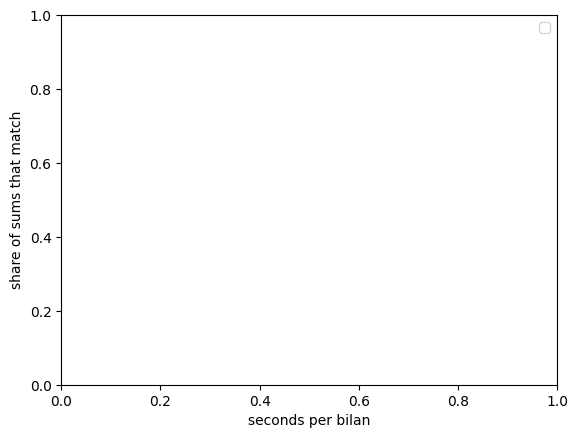

In [22]:
import matplotlib.pyplot as plt

results = table()
results["sums_rate"] = results.sums_ok / results.sums_total.where(results.sums_total > 0)
display(results)
display(results[results.setup == BEST].groupby("model")[["gold_accuracy", "sums_rate", "values_on_page", "seconds", "vram_mb"]].mean().round(3))

best = results[results.setup == BEST]
for model, group in best.groupby("model"):
    plt.scatter(group.seconds, group.sums_rate, label=model)
plt.xlabel("seconds per bilan")
plt.ylabel("share of sums that match")
plt.legend()
plt.show()